In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
import os
import seaborn as sns

In [2]:
# Load data
experiment = 'full_pipeline'
file = f'../experiments/{experiment}/final_data.csv'
df = pd.read_csv(file)

In [15]:
# Filter for sample 1 and exclude fishwater
df_filtered = df[
    (df['sample'] == 1) & 
    (~df['fish'].str.contains('fishwater', case=False))
]

print(df_filtered['sample'].unique())
print(df['fish'].unique())

[1]
<StringArray>
[    'fish1',    'fish10',    'fish12',    'fish13',    'fish14',    'fish15',
    'fish16',    'fish17',    'fish18',     'fish2',    'fish22',    'fish26',
    'fish35',    'fish37',    'fish38',     'fish4',    'fish40',    'fish42',
    'fish44',    'fish45',     'fish5',    'fish50',    'fish51',     'fish8',
 'fishctrl1', 'fishctrl2', 'fishctrl3']
Length: 27, dtype: str


In [16]:
# Define the unedited barcode
none_barcode = "NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE"

In [17]:
# Average proportions across replicates for each fish-barcode combination
PROPORTION_COL = 'proportion'

barcode_props = (
    df_filtered.groupby(['fish', 'barcode'])[PROPORTION_COL]
    .mean()
    .reset_index()
)

# Renormalize so proportions sum to 1.0 for each fish
barcode_props['proportion'] = (
    barcode_props.groupby('fish')['proportion']
    .transform(lambda x: x / x.sum())
)

In [18]:
# Pivot to get barcodes as columns
pivot_df = barcode_props.pivot(index='fish', columns='barcode', values=PROPORTION_COL).fillna(0)

In [19]:
# Collapse replicates: count unique barcodes per fish across all replicates
barcode_counts = (
    df.groupby('fish')['barcode']
    .nunique()
    .reset_index(name='unique_barcode_count')
)

In [20]:
# Sort fish: numerical order first, then 'fishctrl' at the bottom
def sort_fish(fish_name):
    fish_str = str(fish_name).lower()
    if 'ctrl' in fish_str or 'control' in fish_str:
        return (1, fish_str)
    else:
        # Try to extract number from fish name
        import re
        numbers = re.findall(r'\d+', fish_str)
        if numbers:
            return (0, int(numbers[0]))  
        else:
            return (0, fish_str)

fish_list = sorted(pivot_df.index.tolist(), key=sort_fish)
pivot_df = pivot_df.loc[fish_list]
n_fish = len(fish_list)

In [21]:
# Define the base color palette by barcode rank (most abundant → least)
rank_colors = [
    "#ff4d6f", "#579ea4", "#df7713", "#f9c000", "#86ad34",
    "#5d7298", "#81b28d", "#7e1a2f", "#2d2651", "#c8350d", "#bd777a"
]

# If more than 11 barcodes per fish, extend palette
extra_colors = ['#1a5f7a', '#C86BCE', '#75B6FF', '#F9FD7F', '#006400', '#FFC4DE',
                '#FA8072', '#D8FC74', '#571B64', '#00b4d8', '#CA2A6F'
]

# Combine base + extra so it's long enough for all cases
extended_colors = rank_colors + extra_colors

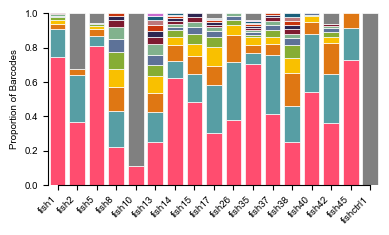

In [22]:
# Figure 1F: Vertical stacked bar plot (fishIDs on x-axis)
plt.rcParams['font.family'] = 'Arial'
fig, ax = plt.subplots(figsize=(max(4, n_fish * 0.135), 2.45))

for i, fish in enumerate(fish_list):
    fish_data = pivot_df.loc[fish]
    fish_data = fish_data[fish_data > 0].sort_values(ascending=False)

    none_prop = fish_data.get(none_barcode, 0)
    other_barcodes = fish_data.drop(none_barcode, errors='ignore')

    n_barcodes = len(other_barcodes)
    colors = [extended_colors[j % len(extended_colors)] for j in range(n_barcodes)]

    bottom = 0
    for j, (barcode, prop) in enumerate(other_barcodes.items()):
        ax.bar(i, prop, bottom=bottom, width=0.8,
               color=colors[j], edgecolor='white', linewidth=0.5)
        bottom += prop

    if none_prop > 0:
        ax.bar(i, none_prop, bottom=bottom, width=0.8,
               color='gray', edgecolor='white', linewidth=0.5)

# Formatting
ax.set_xticks(range(n_fish))
ax.set_xticklabels(fish_list, rotation=45, ha='right', fontsize=7)
ax.tick_params(axis='y', labelsize=7)
ax.set_ylabel('Proportion of Barcodes', fontsize=7)
ax.set_ylim(0, 1)
ax.set_xlim(-0.5, n_fish - 0.5)
sns.despine(trim=True)

handles, labels = ax.get_legend_handles_labels()
if handles:
    ax.legend(loc='upper right', frameon=False)

plt.tight_layout()
#plt.savefig("barcode_proportions_by_fish_ranked_colors_v7_vertical.svg", bbox_inches='tight', transparent=True)
#plt.savefig("barcode_proportions_by_fish_ranked_colors_v7_vertical.png", dpi=600, bbox_inches='tight', transparent=True)
plt.show()